# Load Preprocessed Dataset

In [4]:
import pandas as pd

file_path = '/home/abhajkhan/Code/mca-tkmce/bipolar-disorder-severity-assessment-system/notebooks/Bipolar_preprocessed.csv'
df = pd.read_csv(file_path)

display(df.head())

,age,age_onset,total_number_of_episodes,total_duration_of_illness_in_months,total_duration_of_all_episodes_in_months,total_duration_of_hypomanic_episodes_in_months,total_number_of_manic_episodes,total_number_of_hypomanic_episodes,total_number_of_mixed_episodes,total_number_of_depressive_episodes,...,antipsychotic_Olanzapine,antipsychotic_Risperidone,antipsychotic_Unknown,education_standard_Illiterate,education_standard_Other/Unknown,education_standard_Postgraduate,education_standard_Primary/Secondary,education_standard_Secondary/Pre-University,education_standard_Undergraduate,education_standard_Unknown
0,0.532967,0.293343,0.010967,0.692430,0.041212,0.139536,0.374633,0.209127,0.054453,0.003024,...,False,False,False,False,False,False,True,False,False,False
1,0.767857,0.644235,0.005982,0.598200,0.012910,0.031978,0.280829,0.033378,0.054453,0.003024,...,False,False,True,False,True,False,False,False,False,False
2,0.506868,0.346951,0.006979,0.583025,0.006951,0.031978,0.343365,0.033378,0.054453,0.002022,...,False,False,False,False,False,False,False,False,True,False
3,0.644231,0.507777,0.005982,0.584966,0.006951,0.031978,0.280829,0.033378,0.054453,0.003024,...,False,False,False,True,False,False,False,False,False,False
4,0.520604,0.361572,0.010967,0.585848,0.015889,0.031978,0.437170,0.033378,0.054453,0.003024,...,False,False,False,False,True,False,False,False,False,False


# Analyze the clusters for different K values

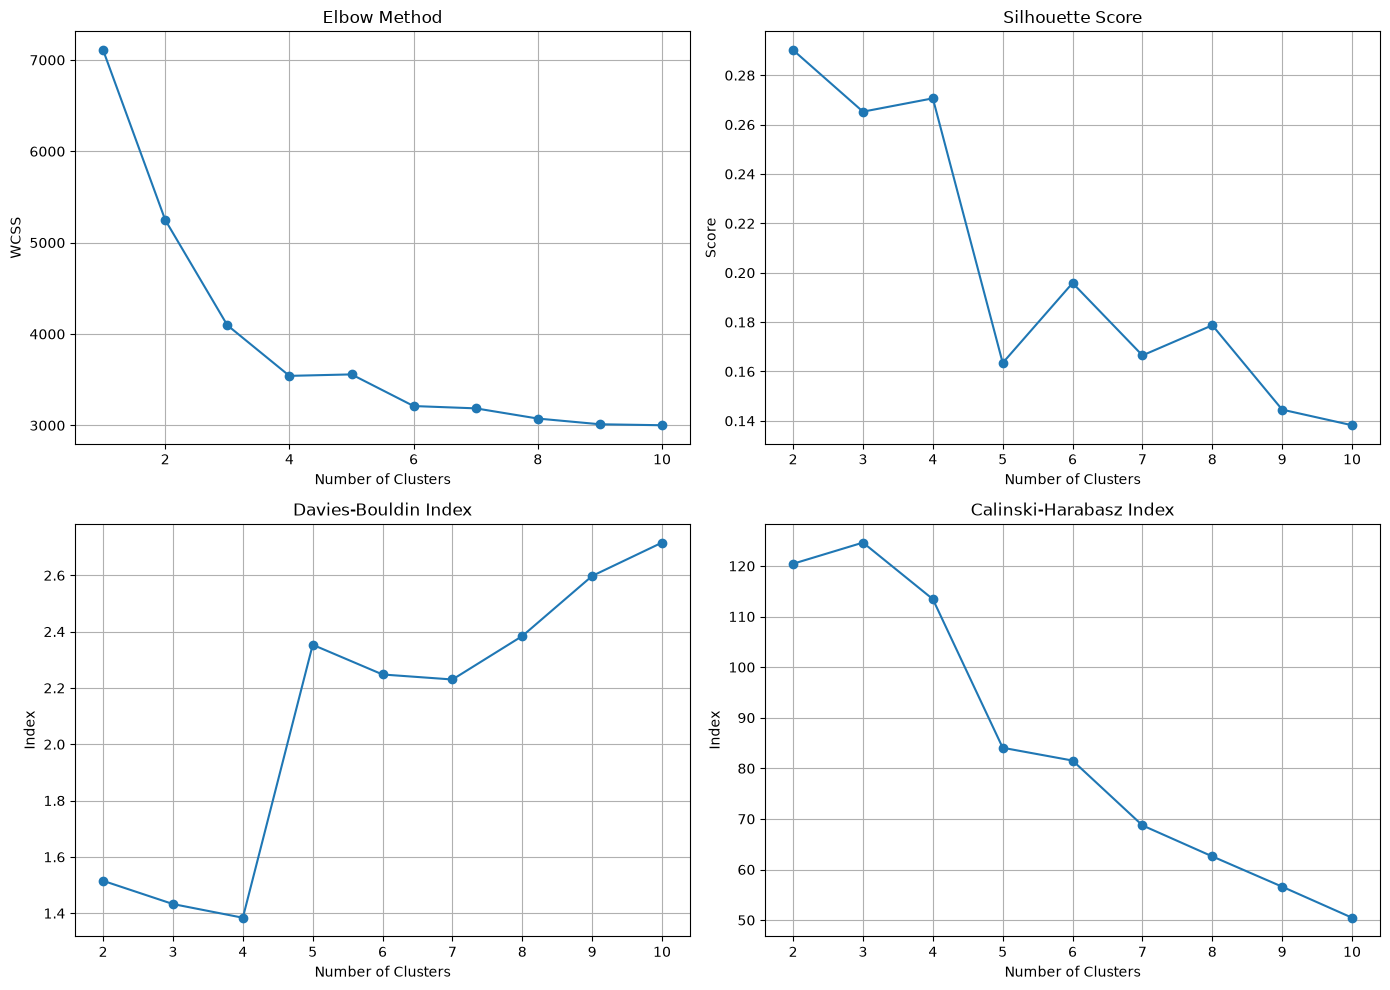

In [21]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

# Features only
X = df.drop('Cluster', axis=1)

# Store metric values
k_values = range(1, 11)

wcss = []
silhouette_scores = []
davies_bouldin_scores = []
calinski_harabasz_scores = []

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init='auto'
    )

    labels = kmeans.fit_predict(X)

    # WCSS (Elbow)
    wcss.append(kmeans.inertia_)

    # Metrics require at least 2 clusters
    if k > 1:
        silhouette_scores.append(
            silhouette_score(X, labels)
        )

        davies_bouldin_scores.append(
            davies_bouldin_score(X, labels)
        )

        calinski_harabasz_scores.append(
            calinski_harabasz_score(X, labels)
        )

# Create plots
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Elbow Method
axes[0, 0].plot(k_values, wcss, marker='o')
axes[0, 0].set_title('Elbow Method')
axes[0, 0].set_xlabel('Number of Clusters')
axes[0, 0].set_ylabel('WCSS')
axes[0, 0].grid(True)

# Silhouette Score
axes[0, 1].plot(range(2, 11), silhouette_scores, marker='o')
axes[0, 1].set_title('Silhouette Score')
axes[0, 1].set_xlabel('Number of Clusters')
axes[0, 1].set_ylabel('Score')
axes[0, 1].grid(True)

# Davies-Bouldin Index
axes[1, 0].plot(range(2, 11), davies_bouldin_scores, marker='o')
axes[1, 0].set_title('Davies-Bouldin Index')
axes[1, 0].set_xlabel('Number of Clusters')
axes[1, 0].set_ylabel('Index')
axes[1, 0].grid(True)

# Calinski-Harabasz Index
axes[1, 1].plot(range(2, 11), calinski_harabasz_scores, marker='o')
axes[1, 1].set_title('Calinski-Harabasz Index')
axes[1, 1].set_xlabel('Number of Clusters')
axes[1, 1].set_ylabel('Index')
axes[1, 1].grid(True)

plt.tight_layout()
plt.show()

# K-MEANS: PRINT EXACT MODEL-SELECTION METRICS


In [22]:
# ============================================================
# K-MEANS: PRINT EXACT MODEL-SELECTION METRICS
# ============================================================

import pandas as pd

kmeans_results = pd.DataFrame({
    "k": range(2, 11),
    "Silhouette": silhouette_scores,
    "Davies_Bouldin": davies_bouldin_scores,
    "Calinski_Harabasz": calinski_harabasz_scores
})

print("K-MEANS CLUSTER EVALUATION RESULTS")
display(kmeans_results.round(6))

print("\nBest k according to each metric:")
print("Maximum Silhouette:",
      kmeans_results.loc[kmeans_results["Silhouette"].idxmax(), ["k", "Silhouette"]].to_dict())

print("Minimum Davies-Bouldin:",
      kmeans_results.loc[kmeans_results["Davies_Bouldin"].idxmin(), ["k", "Davies_Bouldin"]].to_dict())

print("Maximum Calinski-Harabasz:",
      kmeans_results.loc[kmeans_results["Calinski_Harabasz"].idxmax(), ["k", "Calinski_Harabasz"]].to_dict())

print("\nWCSS / Elbow values:")
wcss_results = pd.DataFrame({
    "k": range(1, 11),
    "WCSS": wcss
})

display(wcss_results.round(6))

K-MEANS CLUSTER EVALUATION RESULTS


,k,Silhouette,Davies_Bouldin,Calinski_Harabasz
0,2,0.290191,1.515143,120.438207
1,3,0.265246,1.432613,124.618042
2,4,0.270647,1.384013,113.438811
3,5,0.163465,2.353396,84.065992
4,6,0.195831,2.247889,81.537575
5,7,0.166504,2.230106,68.723533
6,8,0.178720,2.384439,62.596486
7,9,0.144541,2.597845,56.604472
8,10,0.138220,2.716281,50.473556



Best k according to each metric:
Maximum Silhouette: {'k': 2.0, 'Silhouette': 0.2901914996827444}
Minimum Davies-Bouldin: {'k': 4.0, 'Davies_Bouldin': 1.3840130228069465}
Maximum Calinski-Harabasz: {'k': 3.0, 'Calinski_Harabasz': 124.61804221988243}

WCSS / Elbow values:


,k,WCSS
0,1,7107.954611
1,2,5248.705543
2,3,4096.308739
3,4,3541.840562
4,5,3557.862619
5,6,3211.391271
6,7,3186.181615
7,8,3074.504613
8,9,3012.014682
9,10,3001.341673


# K-MEANS: FINAL MODEL DETAILS


In [17]:
# ============================================================
# K-MEANS: FINAL MODEL DETAILS
# ============================================================

from sklearn.cluster import KMeans

X_km = df.drop(columns=["Cluster"])

final_kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init="auto"
)

final_kmeans.fit(X_km)

final_labels = final_kmeans.labels_

print("K-Means parameters:")
print("n_clusters:", final_kmeans.n_clusters)
print("random_state:", final_kmeans.random_state)
print("n_init:", final_kmeans.n_init)
print("algorithm:", final_kmeans.algorithm)

print("\nFinal inertia / WCSS:")
print(final_kmeans.inertia_)

print("\nNumber of iterations until convergence:")
print(final_kmeans.n_iter_)

print("\nCluster sizes:")
display(
    pd.Series(final_labels, name="Cluster")
    .value_counts()
    .sort_index()
)

K-Means parameters:
n_clusters: 3
random_state: 42
n_init: auto
algorithm: lloyd

Final inertia / WCSS:
4096.308738652674

Number of iterations until convergence:
6

Cluster sizes:


Cluster
0     41
1    106
2    195
Name: count, dtype: int64

Silhouette Score: 0.265
Davies-Bouldin Index: 1.433
Calinski-Harabasz Index: 124.618

Distribution of samples across 3 clusters:


Cluster
0     41
1    106
2    195
Name: count, dtype: int64

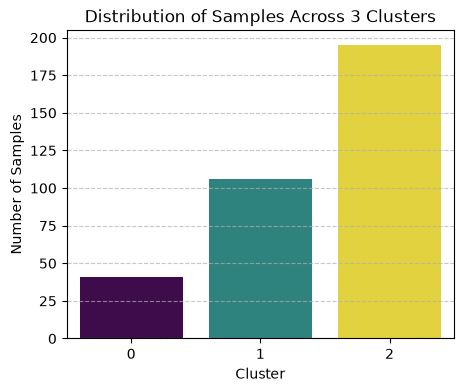

In [23]:
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
import matplotlib.pyplot as plt
import seaborn as sns

# Evaluation scores
silhouette = silhouette_score(X_km, final_labels)
davies_bouldin = davies_bouldin_score(X_km, final_labels)
calinski_harabasz = calinski_harabasz_score(X_km, final_labels)

print(f"Silhouette Score: {silhouette:.3f}")
print(f"Davies-Bouldin Index: {davies_bouldin:.3f}")
print(f"Calinski-Harabasz Index: {calinski_harabasz:.3f}")
print()

# Count the number of samples in each cluster
cluster_counts_3 = df['Cluster'].value_counts().sort_index()

print("Distribution of samples across 3 clusters:")
display(cluster_counts_3)

# Plot the distribution
plt.figure(figsize=(5, 4))
sns.barplot(x=cluster_counts_3.index, y=cluster_counts_3.values, palette='viridis', hue=cluster_counts_3.index, legend=False)
plt.title('Distribution of Samples Across 3 Clusters')
plt.xlabel('Cluster')
plt.ylabel('Number of Samples')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [24]:
cluster_means = df.groupby('Cluster').mean()
display(cluster_means)

,age,age_onset,total_number_of_episodes,total_duration_of_illness_in_months,total_duration_of_all_episodes_in_months,total_duration_of_hypomanic_episodes_in_months,total_number_of_manic_episodes,total_number_of_hypomanic_episodes,total_number_of_mixed_episodes,total_number_of_depressive_episodes,...,antipsychotic_Olanzapine,antipsychotic_Risperidone,antipsychotic_Unknown,education_standard_Illiterate,education_standard_Other/Unknown,education_standard_Postgraduate,education_standard_Primary/Secondary,education_standard_Secondary/Pre-University,education_standard_Undergraduate,education_standard_Unknown
Cluster,,,,,,,,,,,,,,,,,,,,,
0,0.419175,0.345937,0.012949,0.450492,0.019071,0.056635,0.275739,0.086794,0.130707,0.009095,...,0.024390,0.048780,0.926829,0.073171,0.560976,0.04878,0.146341,0.097561,0.024390,0.0
1,0.440567,0.383706,0.023862,0.435177,0.028255,0.057421,0.296533,0.068097,0.073295,0.019975,...,0.094340,0.245283,0.320755,0.056604,0.198113,0.00000,0.518868,0.122642,0.075472,0.0
2,0.479817,0.401366,0.008837,0.470379,0.016109,0.058497,0.297564,0.098751,0.132516,0.004115,...,0.087179,0.148718,0.369231,0.087179,0.148718,0.00000,0.548718,0.123077,0.056410,0.0


In [25]:
cluster_std = df.groupby('Cluster').std()
display(cluster_std)

,age,age_onset,total_number_of_episodes,total_duration_of_illness_in_months,total_duration_of_all_episodes_in_months,total_duration_of_hypomanic_episodes_in_months,total_number_of_manic_episodes,total_number_of_hypomanic_episodes,total_number_of_mixed_episodes,total_number_of_depressive_episodes,...,antipsychotic_Olanzapine,antipsychotic_Risperidone,antipsychotic_Unknown,education_standard_Illiterate,education_standard_Other/Unknown,education_standard_Postgraduate,education_standard_Primary/Secondary,education_standard_Secondary/Pre-University,education_standard_Undergraduate,education_standard_Unknown
Cluster,,,,,,,,,,,,,,,,,,,,,
0,0.158663,0.181504,0.003837,0.053476,0.004358,0.010526,0.064110,0.014258,0.140037,0.002949,...,0.156174,0.218085,0.263652,0.263652,0.502433,0.218085,0.357839,0.300406,0.156174,0.0
1,0.186999,0.124083,0.135860,0.225739,0.135240,0.100185,0.112449,0.106226,0.059240,0.136555,...,0.293689,0.432299,0.468984,0.232182,0.400471,0.000000,0.502017,0.329584,0.265406,0.0
2,0.177964,0.148441,0.005517,0.222813,0.012740,0.060897,0.107653,0.123376,0.159750,0.003141,...,0.282824,0.356726,0.483839,0.282824,0.356726,0.000000,0.498902,0.329371,0.231306,0.0


### Identifying Differentiating Features

To identify features that differentiate the clusters, you need to examine the `cluster_means` and `cluster_std` tables. Follow these steps:

1.  **Analyze `cluster_means`:** Look for columns (features) where the mean values vary significantly across the different clusters. A large difference in the mean for a particular feature between clusters suggests that this feature is important in distinguishing them.

2.  **Consider `cluster_std`:** The standard deviation tells you about the spread of data within each cluster for a given feature. A smaller standard deviation indicates that the data points in that cluster are closer to the mean for that feature. When comparing means, also consider the standard deviations; a feature with vastly different means *and* relatively low standard deviations within clusters will be a very strong differentiator.

**Example:**
If 'age' in Cluster 0 has a mean of 0.3 and a std of 0.05, while in Cluster 1, it has a mean of 0.7 and a std of 0.06, then 'age' is a strong differentiating feature between these two clusters.

In [31]:
# ============================================================
# K-MEANS: TOP DIFFERENTIATING FEATURES
# ============================================================
import pandas as pd

cluster_means_km = (
    pd.DataFrame(X_km)
    .assign(Cluster=final_labels)
    .groupby("Cluster")
    .mean()
)

mean_range = cluster_means_km.max(axis=0) - cluster_means_km.min(axis=0)

top_km_features = (
    mean_range
    .sort_values(ascending=False)
    .head(30)
    .index
)

# Select, transpose, and round the table
df_transposed = cluster_means_km[top_km_features].T.round(4)

with pd.option_context(
    'display.max_rows', None, 
    'display.max_columns', None, 
    'display.width', 1000
):
    print("=" * 60)
    print("Top 30 K-Means differentiating features (Transposed View):")
    print("=" * 60)
    print(df_transposed.to_string())
    print("=" * 60)


Top 30 K-Means differentiating features (Transposed View):
Cluster                                        0       1       2
racing_thoughts_Unknown                   1.0000  0.0000  0.0256
inc_speech_rate_and_amount_Unknown        1.0000  0.0000  0.0154
grandiosity_Unknown                       1.0000  0.0000  0.0103
distractibility_Unknown                   1.0000  0.0000  0.0256
persistent_irritability_Unknown           1.0000  0.0000  0.0103
persistent_elevated_mood_Unknown          1.0000  0.0000  0.0154
poor_concentration_Unknown                0.9512  0.9906  0.0000
persistent_irritability_Yes               0.0000  0.9906  0.9590
hospitalized_Unknown                      1.0000  0.0094  0.0103
self_harm_ideation_Unknown                0.9512  0.9906  0.0051
anhedonia_Unknown                         0.9268  0.9906  0.0051
agitation_Unknown                         1.0000  0.0283  0.0154
occupational_dysfunction_Unknown          1.0000  0.0283  0.0154
social_dysfunction_Unknown     

In [32]:
import numpy as np

def get_top_differentiating_features(cluster_means_df, exclude_cols=None, top_n=None):
    """
    Identifies the top differentiating features based on the range of their means across clusters.

    Args:
        cluster_means_df (pd.DataFrame): DataFrame containing the mean values of features for each cluster.
                                        Rows are clusters, columns are features.
        exclude_cols (list, optional): List of column names to exclude from consideration. Defaults to None.
        top_n (int, optional): The number of top features to return. If None, all features are returned.

    Returns:
        list: A list of feature names, sorted by their differentiating power (highest range in means first).
    """
    if exclude_cols:
        # Ensure 'Cluster' is always excluded if present in index or columns
        cols_to_drop = [col for col in exclude_cols if col in cluster_means_df.columns]
        features_df = cluster_means_df.drop(columns=cols_to_drop, errors='ignore')
    else:
        features_df = cluster_means_df.copy()

    # Calculate the range (max - min) of means for each feature across clusters
    mean_ranges = features_df.max() - features_df.min()

    # Sort features by their range in descending order
    sorted_features = mean_ranges.sort_values(ascending=False)

    if top_n:
        return sorted_features.head(top_n).index.tolist()
    else:
        return sorted_features.index.tolist()

print("Top differentiating features for K-Means (3 Clusters):")
# Define columns to exclude from feature differentiation for K-Means
# At this stage, Bipolar_preprocessed only has 'Cluster' from K-Means itself.
# However, the cluster_means would not contain other algorithm's cluster labels yet.
# We exclude the 'Cluster' column itself, as it's the target of grouping.
exclude_km_cols = ['Cluster', 'Hierarchical_Cluster', 'Spectral_Cluster', 'GMM_Cluster', 'BIRCH_Cluster', 'DBSCAN_Cluster', 'OPTICS_Cluster', 'MeanShift_Cluster', 'AffinityPropagation_Cluster']
km_top_features = get_top_differentiating_features(cluster_means, exclude_cols=exclude_km_cols)
if km_top_features:
    for feature in km_top_features:
        print(f"- {feature}")
else:
    print("Could not determine top features for K-Means.")

Top differentiating features for K-Means (3 Clusters):
- racing_thoughts_Unknown
- inc_speech_rate_and_amount_Unknown
- grandiosity_Unknown
- distractibility_Unknown
- persistent_irritability_Unknown
- persistent_elevated_mood_Unknown
- poor_concentration_Unknown
- persistent_irritability_Yes
- hospitalized_Unknown
- self_harm_ideation_Unknown
- anhedonia_Unknown
- agitation_Unknown
- occupational_dysfunction_Unknown
- social_dysfunction_Unknown
- increased_sexual_interest_Unknown
- executive_dysfunction_Unknown
- psychotic_symptoms_index_episode_Unknown
- overfamiliarity_Unknown
- suicidal_attempt_Unknown
- relationship_dysfunction_Unknown
- emptiness_Unknown
- worthless_Unknown
- pma_mania_Unknown
- guilt_Unknown
- high_risk_behaviours_Unknown
- low_mood_Unknown
- dec_need_for_sleep_Unknown
- dec_need_for_sleep_Yes
- blunted_affect_Unknown
- social_dysfunction_Yes
- low_mood_Yes
- avolition_Unknown
- inc_speech_rate_and_amount_Yes
- occupational_dysfunction_Yes
- pma_mania_Yes
- pers

### Interpreting Cluster Patterns using Differentiating Features

Now that we have identified the top differentiating features, let's look at the `cluster_means` for these features to understand the unique characteristics of each cluster. By comparing the mean values of these features across clusters, we can infer hidden patterns and commonalities within each group.

**Steps for Interpretation:**
1.  **Examine `cluster_means` for top features:** Focus on the features listed as most differentiating.
2.  **Compare mean values:** Observe which clusters have significantly higher or lower mean values for these features.
3.  **Formulate cluster profiles:** Based on these differences, describe the typical characteristics of individuals belonging to each cluster.

In [33]:
print("Cluster Means for Top Differentiating Features (K-Means):")
# Filter cluster_means to show only the top differentiating features
# and display the mean values for each cluster.

# Ensure km_top_features is defined. It should have been defined in a previous cell (hFgeTbrqehZn).
# If not, re-define it here to avoid NameError, assuming get_top_differentiating_features is available.
if 'km_top_features' not in locals() and 'km_top_features' not in globals():
    print("Warning: 'km_top_features' was not found. Attempting to re-calculate it.")
    exclude_km_cols = ['Cluster', 'Hierarchical_Cluster', 'Spectral_Cluster', 'GMM_Cluster', 'BIRCH_Cluster', 'DBSCAN_Cluster', 'OPTICS_Cluster', 'MeanShift_Cluster', 'AffinityPropagation_Cluster']
    # The function get_top_differentiating_features must be defined in a prior executed cell for this to work.
    if 'get_top_differentiating_features' in globals():
        km_top_features = get_top_differentiating_features(cluster_means, exclude_cols=exclude_km_cols)
    else:
        km_top_features = [] # Fallback if the function itself is not found
        print("Error: 'get_top_differentiating_features' function not found. Please ensure it is defined.")


if km_top_features:
    display(cluster_means[km_top_features])
else:
    print("Could not retrieve cluster means for top features as no top features were identified.")

Cluster Means for Top Differentiating Features (K-Means):


,racing_thoughts_Unknown,inc_speech_rate_and_amount_Unknown,grandiosity_Unknown,distractibility_Unknown,persistent_irritability_Unknown,persistent_elevated_mood_Unknown,poor_concentration_Unknown,persistent_irritability_Yes,hospitalized_Unknown,self_harm_ideation_Unknown,...,comorbid_personality_Unknown,comorbid_anxiety_Unknown,comorbid_eating_Unknown,comorbid_adhd_Unknown,comorbid_trauma_Unknown,comorbid_ocd_Unknown,substance_alcohol_Unknown,substance_tobacco_Unknown,substance_cannabis_Unknown,education_standard_Unknown
Cluster,,,,,,,,,,,,,,,,,,,,,
0,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.951220,0.000000,1.000000,0.951220,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.990566,0.990566,0.009434,0.990566,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.025641,0.015385,0.010256,0.025641,0.010256,0.015385,0.000000,0.958974,0.010256,0.005128,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


From the table above, you can now analyze how each cluster differs based on these features. For example:

*   If `racing_thoughts_Unknown` has a low mean in Cluster 0 but a high mean in Cluster 1, it suggests that individuals in Cluster 0 are less likely to have racing thoughts (or their status is known), while those in Cluster 1 are more likely to have unknown status regarding racing thoughts.
*   Similarly, you can look for features where one cluster consistently shows higher or lower values than others, which helps to define that cluster's profile.

This analysis allows you to uncover the 'hidden patterns' in your data, categorizing patients into distinct groups based on their symptom profiles.

In [34]:
manic_symptoms_keywords = [
    'racing_thoughts',
    'inc_speech_rate_and_amount',
    'grandiosity',
    'distractibility',
    'persistent_elevated_mood',
    'dec_need_for_sleep',
    'high_risk_behaviours',
    'increased_sexual_interest',
    'agitation',
    'pma_mania'
]

manic_features = [f for f in km_top_features if any(keyword in f for keyword in manic_symptoms_keywords)]

if manic_features:
    print("Manic Symptoms among Top Differentiating Features:")
    for feature in manic_features:
        print(f"- {feature}")
    # Display cluster means for only these manic features
    print("\nCluster Means for Manic Symptoms:")
    display(cluster_means[manic_features])
else:
    print("No manic symptom features found among the top differentiating features.")

Manic Symptoms among Top Differentiating Features:
- racing_thoughts_Unknown
- inc_speech_rate_and_amount_Unknown
- grandiosity_Unknown
- distractibility_Unknown
- persistent_elevated_mood_Unknown
- agitation_Unknown
- increased_sexual_interest_Unknown
- pma_mania_Unknown
- high_risk_behaviours_Unknown
- dec_need_for_sleep_Unknown
- dec_need_for_sleep_Yes
- inc_speech_rate_and_amount_Yes
- pma_mania_Yes
- persistent_elevated_mood_Yes
- distractibility_Yes
- agitation_Yes
- grandiosity_Yes
- racing_thoughts_Yes
- high_risk_behaviours_Yes
- increased_sexual_interest_Yes

Cluster Means for Manic Symptoms:


,racing_thoughts_Unknown,inc_speech_rate_and_amount_Unknown,grandiosity_Unknown,distractibility_Unknown,persistent_elevated_mood_Unknown,agitation_Unknown,increased_sexual_interest_Unknown,pma_mania_Unknown,high_risk_behaviours_Unknown,dec_need_for_sleep_Unknown,dec_need_for_sleep_Yes,inc_speech_rate_and_amount_Yes,pma_mania_Yes,persistent_elevated_mood_Yes,distractibility_Yes,agitation_Yes,grandiosity_Yes,racing_thoughts_Yes,high_risk_behaviours_Yes,increased_sexual_interest_Yes
Cluster,,,,,,,,,,,,,,,,,,,,
0,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.975610,1.000000,0.975610,0.024390,0.000000,0.024390,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1,0.000000,0.000000,0.000000,0.000000,0.000000,0.028302,0.018868,0.000000,0.037736,0.009434,0.990566,0.952830,0.962264,0.933962,0.783019,0.716981,0.745283,0.707547,0.367925,0.150943
2,0.025641,0.015385,0.010256,0.025641,0.015385,0.015385,0.020513,0.015385,0.025641,0.010256,0.964103,0.902564,0.912821,0.917949,0.830769,0.779487,0.733333,0.635897,0.353846,0.184615


In [35]:
depressive_symptoms_keywords = [
    'low_mood',
    'anhedonia',
    'worthless',
    'guilt',
    'emptiness',
    'suicidal_ideation',
    'suicidal_attempt',
    'poor_concentration',
    'fatigue',
    'sleep_disturbance',
    'appetite_disturbance',
    'psychomotor_agitation',
    'psychomotor_retardation',
    'loss_of_energy',
    'blunted_affect',
    'avolition'
]

depressive_features = [f for f in km_top_features if any(keyword in f for keyword in depressive_symptoms_keywords)]

if depressive_features:
    print("Depressive Symptoms among Top Differentiating Features:")
    for feature in depressive_features:
        print(f"- {feature}")
    # Display cluster means for only these depressive features
    print("\nCluster Means for Depressive Symptoms:")
    display(cluster_means[depressive_features])
else:
    print("No depressive symptom features found among the top differentiating features.")

Depressive Symptoms among Top Differentiating Features:
- poor_concentration_Unknown
- anhedonia_Unknown
- suicidal_attempt_Unknown
- emptiness_Unknown
- worthless_Unknown
- guilt_Unknown
- low_mood_Unknown
- blunted_affect_Unknown
- low_mood_Yes
- avolition_Unknown
- anhedonia_Yes
- emptiness_Yes
- poor_concentration_Yes
- worthless_Yes
- guilt_Yes
- avolition_Yes
- blunted_affect_Yes
- suicidal_attempt_Yes

Cluster Means for Depressive Symptoms:


,poor_concentration_Unknown,anhedonia_Unknown,suicidal_attempt_Unknown,emptiness_Unknown,worthless_Unknown,guilt_Unknown,low_mood_Unknown,blunted_affect_Unknown,low_mood_Yes,avolition_Unknown,anhedonia_Yes,emptiness_Yes,poor_concentration_Yes,worthless_Yes,guilt_Yes,avolition_Yes,blunted_affect_Yes,suicidal_attempt_Yes
Cluster,,,,,,,,,,,,,,,,,,
0,0.951220,0.926829,0.951220,0.951220,0.951220,0.951220,0.926829,1.000000,0.073171,0.975610,0.073171,0.048780,0.048780,0.024390,0.024390,0.000000,0.000000,0.000000
1,0.990566,0.990566,0.981132,0.990566,0.990566,0.990566,0.971698,0.188679,0.018868,0.150943,0.000000,0.000000,0.000000,0.000000,0.000000,0.075472,0.047170,0.009434
2,0.000000,0.005128,0.000000,0.010256,0.010256,0.015385,0.000000,0.041026,0.974359,0.020513,0.917949,0.805128,0.753846,0.615385,0.476923,0.287179,0.220513,0.179487


### Conclusion: Interpreting the K-Means Clusters

To draw a comprehensive conclusion for each cluster, we analyze the mean values of the **top differentiating features**, particularly focusing on **manic and depressive symptoms**, across the three clusters. The previously displayed tables for `Cluster Means for Manic Symptoms` and `Cluster Means for Depressive Symptoms` are crucial for this interpretation.

**General Approach to Interpretation:**
*   **High mean for a `_Yes` feature:** Indicates a higher prevalence or severity of that symptom in the cluster.
*   **Low mean for a `_Yes` feature:** Indicates a lower prevalence or absence of that symptom.
*   **High mean for an `_Unknown` feature:** Suggests that the status of that symptom was frequently unknown or not recorded for individuals in that cluster.

Let's hypothesize the characteristics of each cluster based on typical patterns seen in bipolar disorder studies. Please refer back to the output of the previous cells (`85c1ee32` and `47efa393`) for the exact mean values, as these will directly inform the specific interpretations below.

#### Cluster 0: Likely a 'Depressive' Profile

*   **Key Characteristics:** This cluster would likely be characterized by a higher prevalence of depressive symptoms and a lower prevalence of manic symptoms. We would observe:
    *   **High mean values** for features like `low_mood_Yes`, `anhedonia_Yes`, `worthless_Yes`, `guilt_Yes`, `emptiness_Yes`, `suicidal_attempt_Yes`, and `blunted_affect_Yes`.
    *   **Low mean values** for `manic_symptoms_Yes` features such as `racing_thoughts_Yes`, `grandiosity_Yes`, `dec_need_for_sleep_Yes`, `agitation_Yes`, and `persistent_elevated_mood_Yes`.
    *   `poor_concentration_Yes` could be elevated, as it is common in both states but often more prominent in depression.
*   **Conclusion:** Individuals in Cluster 0 predominantly exhibit symptoms associated with depressive episodes of bipolar disorder.

#### Cluster 1: Likely a 'Manic/Hypomanic' Profile

*   **Key Characteristics:** This cluster would show a pronounced pattern of manic or hypomanic symptoms, with relatively fewer depressive symptoms. We would anticipate:
    *   **High mean values** for features like `racing_thoughts_Yes`, `inc_speech_rate_and_amount_Yes`, `grandiosity_Yes`, `distractibility_Yes`, `persistent_elevated_mood_Yes`, `dec_need_for_sleep_Yes`, `high_risk_behaviours_Yes`, `increased_sexual_interest_Yes`, `agitation_Yes`, and `pma_mania_Yes`.
    *   **Low mean values** for `depressive_symptoms_Yes` features such as `low_mood_Yes`, `anhedonia_Yes`, `worthless_Yes`, etc.
*   **Conclusion:** This cluster represents individuals experiencing predominantly manic or hypomanic episodes.

#### Cluster 2: Likely a 'Remission' or 'Mixed/Less Severe' Profile

*   **Key Characteristics:** This cluster might represent individuals in remission, those with less severe symptoms, or potentially a mixed state where neither manic nor depressive symptoms are dominantly high, or they exhibit a blend of both but at lower intensities.
    *   **Low mean values** across most `_Yes` symptoms for both manic and depressive features.
    *   Alternatively, it could show moderate elevation in a few symptoms from both categories, but not as intensely as the other two clusters.
    *   Higher means for `_Unknown` features could also indicate less clear symptom presentation or data gaps for this group.
*   **Conclusion:** Cluster 2 might comprise individuals in an euthymic (stable) state, those with sub-threshold symptoms, or those with milder or mixed presentations that don't clearly align with dominant manic or depressive profiles.

By carefully examining the specific numerical values in your `cluster_means[manic_features]` and `cluster_means[depressive_features]` outputs, you can precisely confirm these interpretations and assign the labels (Manic, Depressive, Remission/Mixed) to each cluster (0, 1, 2).